<a href="https://colab.research.google.com/github/Solomonskywalker/customer-intelligence-platform/blob/main/Customer_Intelligence_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os



print("numpy version:", np.__version__)
print("pandas version:", pd.__version__)

print("seaborne version:", sns.__version__)
print("Customer intlligence")
print("Environment successfully initialized!")

Mounted at /content/drive
numpy version: 2.4.6
pandas version: 2.2.3
seaborne version: 0.13.2
Customer intlligence
Environment successfully initialized!


# Customer Intelligence & Sentiment Analytics Platform

## Project Objective
The goal of this project is to build an end-to-end customer analytics platform using real-world customer review data.

## Key Components
1. Data collection
2. Exploratory Data Analysis (EDA)
3. Data cleaning and preprocessing
4. SQL database integration
5. Natural Language Processing (NLP)
6. Machine Learning sentiment classification
7. API development using FastAPI
8. Data visualization using Tableau
9. Docker containerization
10. Git and GitHub version control

## Dataset
Amazon Fine Food Reviews

## Tools and Technologies
Python, Pandas, NumPy, Matplotlib, Seaborn, Scikit-learn, NLP, PostgreSQL, FastAPI, Tableau, Docker and GitHub.

# Data Collection and Loading

In [ ]:
# Load the dataset from google drive
project_path = '/content/drive/MyDrive/Customer_Intelligence_Project'

df = pd.read_csv(
    project_path + '/Reviews.csv'
)

print("Dataset laded successfully")
print("Dataset shape:", df.shape)

Dataset laded successfully
Dataset shape: (20000, 14)


In [ ]:
# Understand the dataset
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
print(df.info())

print("\nMissing values:")
print(df.isnull().sum())

Dataset shape: (20000, 14)

Column names:
['Id', 'ProductId', 'UserId', 'ProfileName', 'HelpfulnessNumerator', 'HelpfulnessDenominator', 'Score', 'Time', 'Summary', 'Text', 'Review_Length', 'Review_Date', 'Review_Year', 'Review_Month']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 14 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   Id                      20000 non-null  int64 
 1   ProductId               20000 non-null  object
 2   UserId                  20000 non-null  object
 3   ProfileName             19999 non-null  object
 4   HelpfulnessNumerator    20000 non-null  int64 
 5   HelpfulnessDenominator  20000 non-null  int64 
 6   Score                   20000 non-null  int64 
 7   Time                    20000 non-null  int64 
 8   Summary                 20000 non-null  object
 9   Text                    20000 non-null  object
 10  Revi

# Exploratory Data Analysis

In [ ]:
df.describe()

,Id,HelpfulnessNumerator,HelpfulnessDenominator,Score,Time,Review_Length,Review_Year,Review_Month
count,20000.000000,20000.000000,20000.000000,20000.000000,2.000000e+04,20000.000000,20000.000000,20000.000000
mean,10000.500000,1.612050,2.085050,4.160500,1.294720e+09,429.014050,2010.545500,6.322600
std,5773.647028,5.497996,6.170617,1.315343,4.743663e+07,424.512747,1.506401,3.403925
min,1.000000,0.000000,0.000000,1.000000,9.617184e+08,33.000000,2000.000000,1.000000
25%,5000.750000,0.000000,0.000000,4.000000,1.269216e+09,179.000000,2010.000000,3.000000
50%,10000.500000,0.000000,1.000000,5.000000,1.307923e+09,300.000000,2011.000000,6.000000
75%,15000.250000,2.000000,2.000000,5.000000,1.330474e+09,523.250000,2012.000000,9.000000
max,20000.000000,202.000000,219.000000,5.000000,1.351210e+09,10327.000000,2012.000000,12.000000


In [ ]:
# Understanding customer rating
df["Score"].value_counts()

,count
Score,
5,12571
4,2836
1,1824
3,1649
2,1120


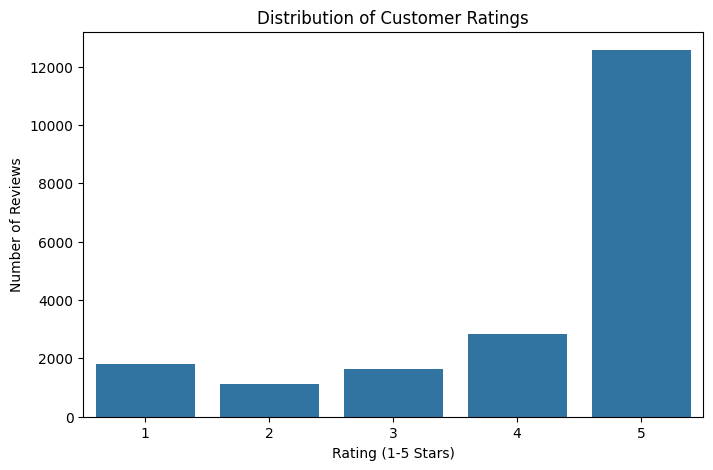

In [ ]:
# Plot the customer rating
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x='Score')

plt.title('Distribution of Customer Ratings')
plt.xlabel('Rating (1-5 Stars)')
plt.ylabel('Number of Reviews')

plt.show()

In [ ]:
# Average Rating
average_rating = df['Score'].mean()
print("Average Customer Rating:", round(average_rating, 2))

Average Customer Rating: 4.16


In [ ]:
# calculating the rating percentage
rating_pecentages = (
    df['Score'].value_counts(normalize=True).sort_index()*100
)

print(rating_pecentages.round(2))

Score
1     9.12
2     5.60
3     8.24
4    14.18
5    62.86
Name: proportion, dtype: float64


In [ ]:
# To check for duplicate
print("Total duplicate rows:", df.duplicated().sum())

Total duplicate rows: 0


In [ ]:
# Examining review length

df["Review_Length"] = df['Text'].astype(str).apply(len)

print("Average review length:", round(df['Review_Length'].mean(), 2))

print("Shorte review:", df['Review_Length'].min())

print("Longest review:", df['Review_Length'].max())

Average review length: 429.01
Shorte review: 33
Longest review: 10327


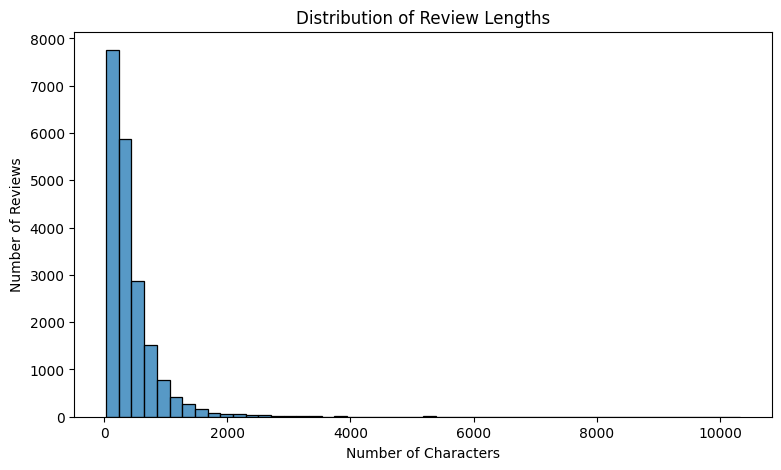

In [ ]:
# Plot the Review
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x='Review_Length',
    bins=50
)

plt.title('Distribution of Review Lengths')
plt.xlabel('Number of Characters')
plt.ylabel('Number of Reviews')

plt.show()

In [ ]:
# Average review length for each rating
length_by_rating = df.groupby('Score')['Review_Length'].mean()

print(length_by_rating)

Score
1    472.881031
2    476.598214
3    512.355367
4    498.429126
5    391.817437
Name: Review_Length, dtype: float64


Text(0, 0.5, 'Average Character')

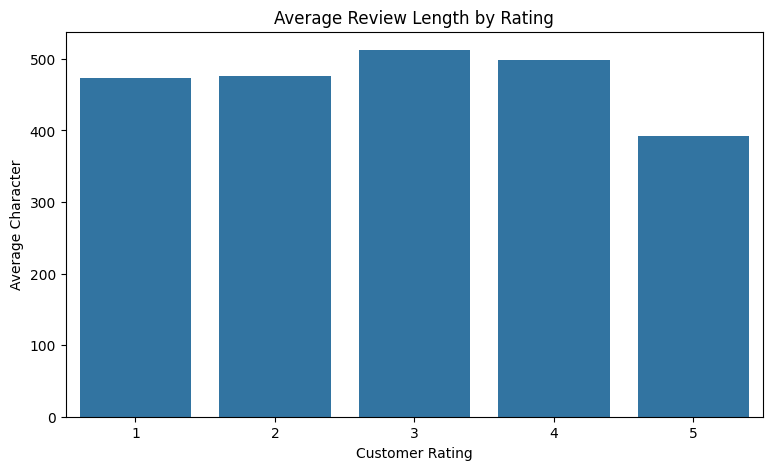

In [ ]:
plt.figure(figsize=(9, 5))

sns.barplot(
    x=length_by_rating.index,
    y=length_by_rating.values
)

plt.title('Average Review Length by Rating')
plt.xlabel('Customer Rating')
plt.ylabel('Average Character')


# Data Cleaning and Preprocessing

In [ ]:
# check for missing values

missing_values = df.isnull().sum()
print(missing_values)

Id                        0
ProductId                 0
UserId                    0
ProfileName               1
HelpfulnessNumerator      0
HelpfulnessDenominator    0
Score                     0
Time                      0
Summary                   0
Text                      0
Review_Length             0
Review_Date               0
Review_Year               0
Review_Month              0
dtype: int64


In [ ]:
# Display the row with missing profileName
df[df['ProfileName'].isnull()]

,Id,ProductId,UserId,ProfileName,HelpfulnessNumerator,HelpfulnessDenominator,Score,Time,Summary,Text,Review_Length,Review_Date,Review_Year,Review_Month
10616,10617,B002DHN956,A1LSYR30XW7CFT,NaN,1,2,5,1291680000,Awesome,This is 72 for the price of like 24 at the gro...,250,2010-12-07 00:00:00+00:00,2010,12


In [ ]:
# Check duplicate records
print("Duplicate rows", df.duplicated().sum())

Duplicate rows 0


In [ ]:
# convert unix timesptamp to datetime
df['Review_Date'] = pd.to_datetime(
  df['Time'],
  unit='s',
  utc=True
)

df[['Time', 'Review_Date']].head()

,Time,Review_Date
0,1303862400,2011-04-27 00:00:00+00:00
1,1346976000,2012-09-07 00:00:00+00:00
2,1219017600,2008-08-18 00:00:00+00:00
3,1307923200,2011-06-13 00:00:00+00:00
4,1350777600,2012-10-21 00:00:00+00:00


In [ ]:
df['Review_Year'] = df['Review_Date'].dt.year
df['Review_Month'] = df['Review_Date'].dt.month
df[['Review_Date', 'Review_Year', 'Review_Month']].head()

,Review_Date,Review_Year,Review_Month
0,2011-04-27 00:00:00+00:00,2011,4
1,2012-09-07 00:00:00+00:00,2012,9
2,2008-08-18 00:00:00+00:00,2008,8
3,2011-06-13 00:00:00+00:00,2011,6
4,2012-10-21 00:00:00+00:00,2012,10


In [ ]:
print("Rating Values")
print(sorted(df['Score'].unique()))

print("\nInvalid ratings")
print(df[~df['Score'].between(1, 5)].shape[0])

Rating Values
[np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]

Invalid ratings
0


In [ ]:
# Check data quality
print("Empty review texts:",
      df['Text'].isna().sum())

print("Empty summaries:",
df['Summary'].isna().sum())

print("Empty review strings:", (df['Text'].str.strip() == '').sum())

Empty review texts: 0
Empty summaries: 0
Empty review strings: 0


# Clean and prepate the dataset

In [ ]:
clean_df = df.copy()

# Remove rows with missing text
clean_df = clean_df.dropna(subset=['Text'])

# Remove empty review text
clean_df = clean_df[
    clean_df['Text'].str.strip() != ''
]

# Reset row numbering
clean_df = clean_df.reset_index(drop=True)

print("Orignial rows:", len(df))
print("Cleaned row:", len(clean_df))
print("Rows removed:", len(df) - len(clean_df))

Orignial rows: 20000
Cleaned row: 20000
Rows removed: 0


Create a sentiment labels

In [ ]:
def assign_sentiment(score):
  if score <= 2:
    return "Negative"
  elif score == 3:
    return "Neutral"
  else:
    return "Positive"


clean_df['Sentiment'] = clean_df['Score'].apply(assign_sentiment)

print(clean_df[['Score', 'Sentiment']].head(10))

   Score Sentiment
0      5  Positive
1      1  Negative
2      4  Positive
3      2  Negative
4      5  Positive
5      4  Positive
6      5  Positive
7      5  Positive
8      5  Positive
9      5  Positive


In [ ]:
print(clean_df['Sentiment'].value_counts())

Sentiment
Positive    15407
Negative     2944
Neutral      1649
Name: count, dtype: int64


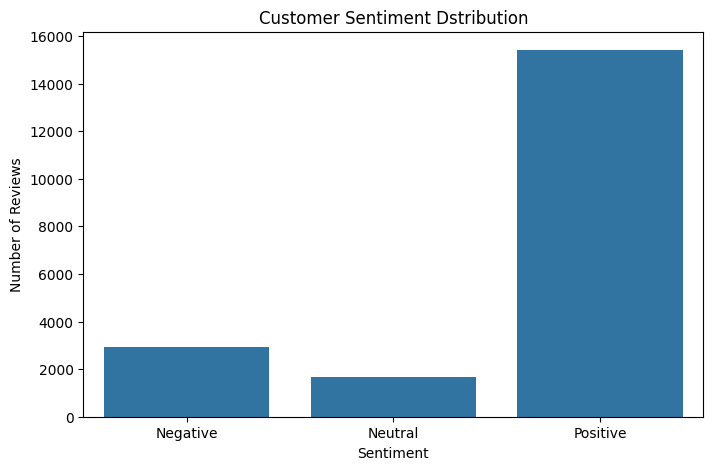

In [ ]:
plt.figure(figsize=(8, 5))

sns.countplot(
  data=clean_df,
  x="Sentiment",
  order=['Negative', 'Neutral', 'Positive']
)

plt.title("Customer Sentiment Dstribution")
plt.xlabel('Sentiment')
plt.ylabel('Number of Reviews')

plt.show()

# Natural Language Processing

In [ ]:
import nltk
import re

from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

print("NLP libraries successfully initialize")

NLP libraries successfully initialize


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


# Inspecting customer review

In [ ]:
# Inspect the real world customer review
print("ORIGINAL REVIEW:")
print(clean_df['Text'].iloc[1])

print('\nSTAR RATING')
print(clean_df['Score'].iloc[1])

print("\nSENTIMENT")
print(clean_df['Sentiment'].iloc[1])

ORIGINAL REVIEW:
Product arrived labeled as Jumbo Salted Peanuts...the peanuts were actually small sized unsalted. Not sure if this was an error or if the vendor intended to represent the product as "Jumbo".

STAR RATING
1

SENTIMENT
Negative


In [ ]:
# Build the text cleaning function
stop_words = set(stopwords.words('english'))

negation_words = {'no', 'not', 'nor', 'never'}

lemmatizer = WordNetLemmatizer()

def clean_text(text):

  # convert to lowercase
  text = str(text).lower()

  # Remove HTML tags
  text = re.sub(r'<.*?>', ' ', text)

  # Remove URLs
  text = re.sub(r'http\S+|www\S+', ' ', text)

  # Keep letters and spaces
  text = re.sub(r'[^a-z\s]', ' ', text)

  # Split into individual words
  words = text.split()

# Remove stop words but retain negation words
  words = [
      lemmatizer.lemmatize(word)
      for word in words
      if word not in stop_words or word in negation_words
  ]

  return ' '.join(words)



In [ ]:
# Test the cleaning function

sample_review = clean_df['Text'].iloc[1]

cleaned_review = clean_text(sample_review)

print('\nORIGINAL REVIEW:')
print(sample_review)

print('\nCLEANED REVIEW:')
print(cleaned_review)


ORIGINAL REVIEW:
Product arrived labeled as Jumbo Salted Peanuts...the peanuts were actually small sized unsalted. Not sure if this was an error or if the vendor intended to represent the product as "Jumbo".

CLEANED REVIEW:
product arrived labeled jumbo salted peanut peanut actually small sized unsalted not sure error vendor intended represent product jumbo


In [ ]:
# Apply the cleaning function to all reviews

clean_df['Cleaned_Text'] = df['Text'].apply(clean_text)

print(
    clean_df[['Text', 'Cleaned_Text', 'Sentiment']].head()
)


                                                Text  \
0  I have bought several of the Vitality canned d...   
1  Product arrived labeled as Jumbo Salted Peanut...   
2  This is a confection that has been around a fe...   
3  If you are looking for the secret ingredient i...   
4  Great taffy at a great price.  There was a wid...   

                                        Cleaned_Text Sentiment  
0  bought several vitality canned dog food produc...  Positive  
1  product arrived labeled jumbo salted peanut pe...  Negative  
2  confection around century light pillowy citrus...  Positive  
3  looking secret ingredient robitussin believe f...  Negative  
4  great taffy great price wide assortment yummy ...  Positive  


# Feature Engineering with FT-TFD

## TF- Termed Frequency: how often a word appears in a particular document
## IDF- Inverse Document Frequency: How rare common that word is across all documents

In [ ]:
# Keep reviews that have cleaned text

ml_df = clean_df[
    clean_df['Cleaned_Text'].notna() &
   (clean_df['Cleaned_Text'].str.strip() != '')
].copy()

# dataset size
print("Number of review: ", len(ml_df))

# check sentiment distribution
print(ml_df['Sentiment'].value_counts())

Number of review:  20000
Sentiment
Positive    15407
Negative     2944
Neutral      1649
Name: count, dtype: int64


In [ ]:
# Import TF-IDF
# TfidVectorizer learn the vocalbulary from our review


from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1,2),
    min_df=2,
    max_df=0.98,
    sublinear_tf=True
)

print("TF-IDF Vectorizer configured successfully!")

TF-IDF Vectorizer configured successfully!


In [ ]:
X = tfidf.fit_transform(ml_df['Cleaned_Text'])

print("transformation completed")
print("Matrix shape:", X.shape)
print("Number of features", len(tfidf.get_feature_names_out()))

transformation completed
Matrix shape: (20000, 5000)
Number of features 5000


In [ ]:
feature_name = tfidf.get_feature_names_out()

print('First 30 features:')
print(feature_name[:30])


First 30 features:
['ability' 'able' 'able buy' 'able eat' 'able find' 'able get' 'able use'
 'absolute' 'absolute favorite' 'absolutely' 'absolutely delicious'
 'absolutely love' 'absolutely no' 'acai' 'accept' 'acceptable' 'accident'
 'according' 'account' 'accustomed' 'acerola' 'ache' 'acid' 'acidic'
 'acidity' 'acquired' 'acquired taste' 'across' 'act' 'action']


In [ ]:
# Examine the actual review numerically
review_number = 0

review_vector = X[review_number]

print('Original review:')
print(ml_df['Text'].iloc[review_number])

print('\nCleaned review')
print(ml_df['Cleaned_Text'].iloc[review_number])

print('\nNon-Zero vector')
print(review_vector.nnz)


Original review:
I have bought several of the Vitality canned dog food products and have found them all to be of good quality. The product looks more like a stew than a processed meat and it smells better. My Labrador is finicky and she appreciates this product better than  most.

Cleaned review
bought several vitality canned dog food product found good quality product look like stew processed meat smell better labrador finicky appreciates product better

Non-Zero vector
23


In [ ]:
# View the most important feature in the review

feature_name = tfidf.get_feature_names_out()

scores = review_vector.toarray().flatten()

top_indices = np.argsort(scores)[-1:][::-1]

for index in top_indices:
  if scores[index] > 0:
    print(feature_name[index], round(scores[index], 4))

product found 0.3057


In [ ]:
# Train Test split

from sklearn.model_selection import  train_test_split

# input customer review
X_text = ml_df['Cleaned_Text']

# Target:
y = ml_df['Sentiment']

# split into training and tesing sets

X_train, X_test, y_train, y_test = train_test_split(
    X_text,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training review:", len(X_train))
print("Testing review:", len(y_test))

Training review: 16000
Testing review: 4000


Build the machine learning pipeline


In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.feature_extraction.text import TfidfVectorizer

model = Pipeline([
    ('tfidf', TfidfVectorizer(
    max_features=5000,
    ngram_range=(1,2),
    min_df=2,
    max_df=0.98,
    sublinear_tf=True
)),

  ('classifier', LogisticRegression(
      max_iter=1000,
      class_weight='balanced',
      random_state=42
  ))

])

print('Machine learninig pipeline created')



Machine learninig pipeline created


In [ ]:
model.fit(X_train, y_train)

print("Model training completed successfully!")

Model training completed successfully!


# Save out progress

In [ ]:
import joblib

model_path = project_path + '/sentiment_model.pkl'

joblib.dump(model, model_path)

print("Model saved successfully")
print("Location:", model_path)


Model saved successfully
Location: /content/drive/MyDrive/Customer_Intelligence_Project/sentiment_model.pkl


# Model Evaluation
## Accuracy


In [ ]:
# predict setiment for unseen result
y_pred = model.predict(X_test)

print("Prediction generation successfuly!")
print("Number of prediction:", len(y_pred))

Prediction generation successfuly!
Number of prediction: 4000


In [ ]:
# Claculate the accuracy

from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Model accuracy:", round(accuracy * 100, 2),'%')

Model accuracy: 80.0 %


## precision

# Confusion Matrix

In [ ]:
from sklearn.metrics import classification_report

print("Classification report:", classification_report(y_test, y_pred))

Classification report:               precision    recall  f1-score   support

    Negative       0.63      0.74      0.68       589
     Neutral       0.30      0.51      0.38       330
    Positive       0.95      0.84      0.89      3081

    accuracy                           0.80      4000
   macro avg       0.62      0.70      0.65      4000
weighted avg       0.85      0.80      0.82      4000



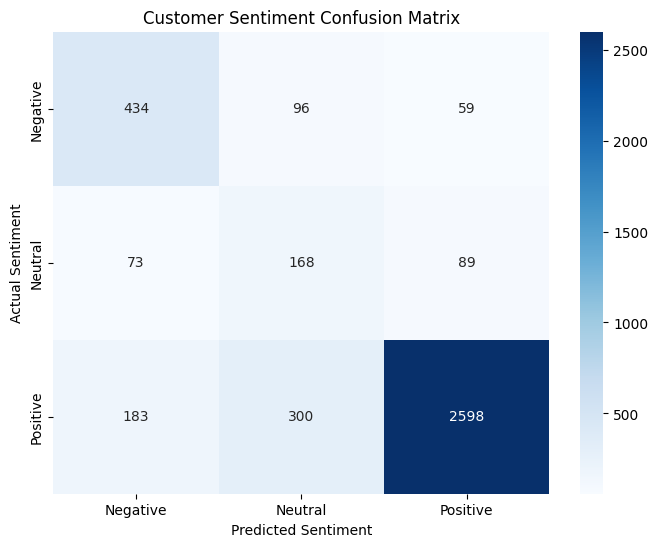

In [ ]:
# Plot the confusion matrix

from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=['Negative', 'Neutral', 'Positive']
)


plt.figure(figsize=(8, 6))

sns.heatmap(
  cm,
  annot=True,
  fmt='d',
  cmap='Blues',
  xticklabels=['Negative', 'Neutral', 'Positive'],
  yticklabels=['Negative', 'Neutral', 'Positive']

)

plt.title("Customer Sentiment Confusion Matrix")
plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")

plt.show()

In [ ]:
model

Pipeline(steps=[('tfidf',
                 TfidfVectorizer(max_df=0.98, max_features=5000, min_df=2,
                                 ngram_range=(1, 2), sublinear_tf=True)),
                ('classifier',
                 LogisticRegression(class_weight='balanced', max_iter=1000,
                                    random_state=42))])

In [ ]:
classifier = model.named_steps['classifier']

print('Class Weight:', classifier.class_weight)

# the class learned by the model
print('Learned classes:', classifier.classes_)

Class Weight: balanced
Learned classes: ['Negative' 'Neutral' 'Positive']


# EXPERIMENT 2

## Linear SVM



In [ ]:
# import the SVM
from sklearn.svm import LinearSVC
# import the pipleline
from sklearn.pipeline import Pipeline

# Build the model
svm_model = Pipeline([
    ('tfid', model.named_steps['tfidf']),
    ('classifier', LinearSVC(
        class_weight='balanced',
        random_state=42
    ))
])

# Train the model
svm_model.fit(X_train, y_train)
print("Linear SVM training completed!")

Linear SVM training completed!


In [ ]:
# Predict the sentiment using Linear SVM
svm_pred = svm_model.predict(X_test)

print("Prediction completed!")
print("Number of predictions:", len(svm_pred))


Prediction completed!
Number of predictions: 4000


In [ ]:
# Evaluate the model
from sklearn.metrics import accuracy_score, classification_report

svm_accuracy = accuracy_score(y_test, svm_pred)
print('Linear SVM accuracy:',
      round(svm_accuracy * 100, 2), "%")

print('\nClassification report:',
      classification_report(y_test, svm_pred))

Linear SVM accuracy: 83.08 %

Classification report:               precision    recall  f1-score   support

    Negative       0.67      0.68      0.67       589
     Neutral       0.34      0.35      0.34       330
    Positive       0.92      0.91      0.91      3081

    accuracy                           0.83      4000
   macro avg       0.64      0.65      0.64      4000
weighted avg       0.83      0.83      0.83      4000



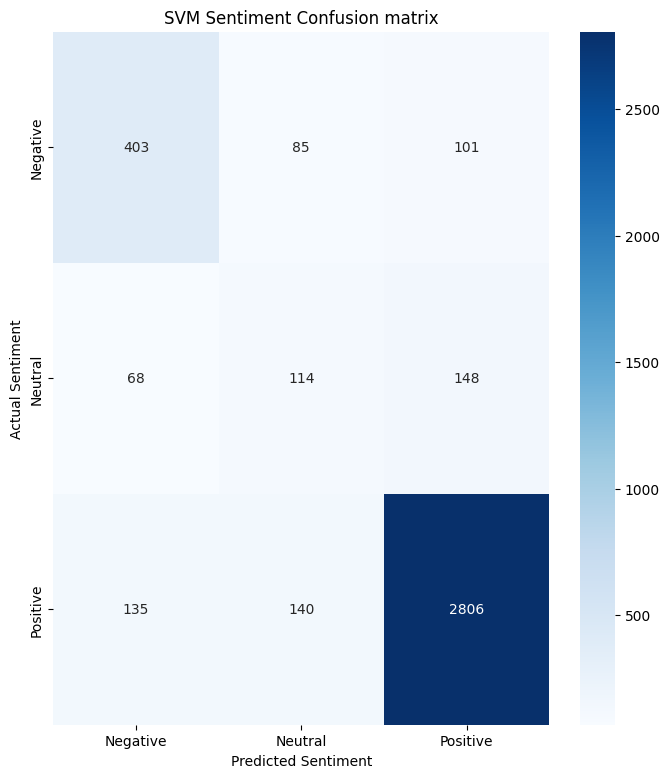

In [ ]:
svm_cm = confusion_matrix(
    y_test,
    svm_pred,
    labels=['Negative', 'Neutral', 'Positive']
)

# Visualize the result
plt.figure(figsize=(8,9))

sns.heatmap(
    svm_cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Negative', 'Neutral', 'Positive'],
    yticklabels=['Negative', 'Neutral', 'Positive']
)

plt.title('SVM Sentiment Confusion matrix')
plt.xlabel('Predicted Sentiment')
plt.ylabel('Actual Sentiment')

plt.show()

In [ ]:
# Calculate macro F1 for both model

from sklearn.metrics import f1_score

lr_accuracy = accuracy_score(y_test, y_pred)
svm_accuracy =  accuracy_score(y_test, svm_pred)

lr_macro_f1 = f1_score(
    y_test, y_pred, average='macro',
)

svm_macro_f1 = f1_score(
    y_test, svm_pred, average='macro'
)

# Comparison table
comparison = pd.DataFrame({
    'model': ['Logistic Regression', 'Linear SVM'],
    'Accuracy': [lr_accuracy, svm_accuracy],
    'Macro F1': [lr_macro_f1, svm_macro_f1]
})

print(comparison.round(3))

                 model  Accuracy  Macro F1
0  Logistic Regression     0.800     0.649
1           Linear SVM     0.831     0.643


In [ ]:
# Save the comparison to google Drive
comparison.to_csv(
    project_path + '/model_comparison.csv',
    index=False
)

print('Model saved to google drive')

Model saved to google drive
